World and Economic Analysis

Is there a correlation between a country's economic output (GDP) and its citizens' overall life expectancy, and how does that relationship compare across six different nations?

First, I'll set up our imports:

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

Second, I'll load and inspect the data:

In [2]:
df = pd.read_csv('all_data.csv')
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           96 non-null     object 
 1   Year                              96 non-null     int64  
 2   Life expectancy at birth (years)  96 non-null     float64
 3   GDP                               96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB


Exploratory Data Analysis:

In [3]:
df.describe()
df.groupby('Country').mean(numeric_only=True)

,Year,Life expectancy at birth (years),GDP
Country,,,
Chile,2007.5,78.94375,1.697888e+11
China,2007.5,74.26250,4.957714e+12
Germany,2007.5,79.65625,3.094776e+12
Mexico,2007.5,75.71875,9.766506e+11
United States of America,2007.5,78.06250,1.407500e+13
Zimbabwe,2007.5,50.09375,9.062580e+09


Visualizations and Comparative Analysis:

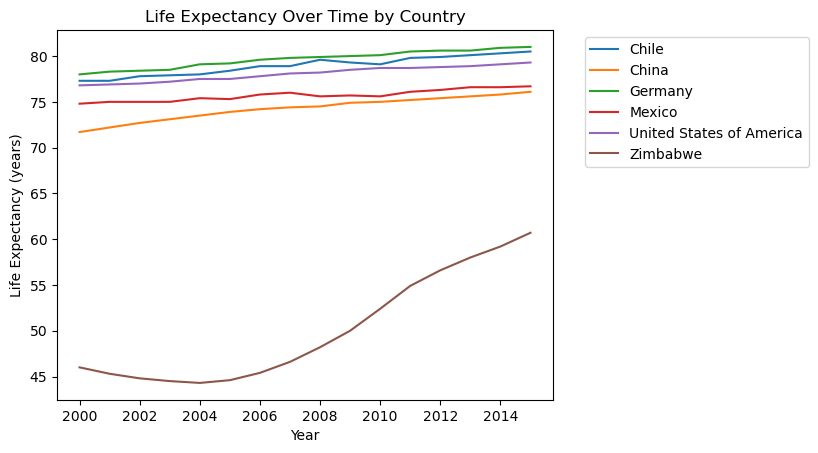

In [5]:
# Use Seaborn lineplot to track life expectancy over years for each country
sns.data = df
sns.lineplot(data=df, x="Year", y="Life expectancy at birth (years)", hue="Country")
plt.title("Life Expectancy Over Time by Country")
plt.ylabel("Life Expectancy (years)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Moves legend outside the plot
plt.show()

Has life expectancy increased over time in the six nations? 

Yes, every single nation in the dataset shows an overall upward trajectory from 2000 to 2015.For most nations, the trend is a steady climb. While there is one massive outlier below the tight cluster of the rest of the countries, they all still end in an increase of life expectancy with time.

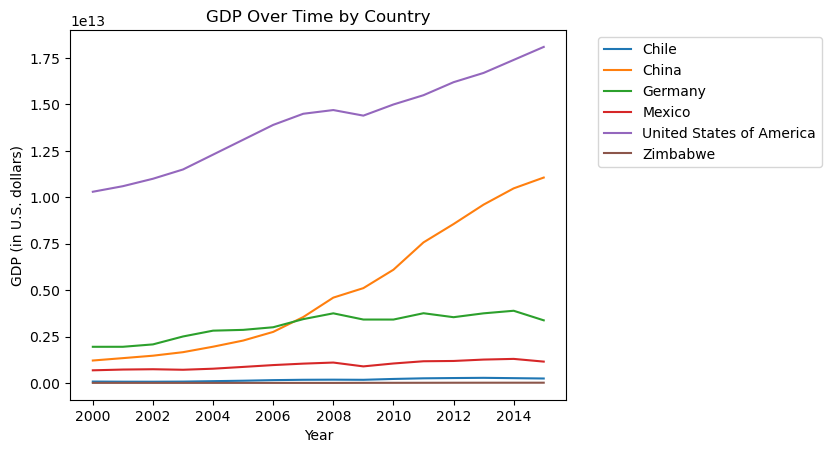

In [6]:
sns.lineplot(data=df, x="Year", y="GDP", hue="Country")
plt.title("GDP Over Time by Country")
plt.ylabel("GDP (in U.S. dollars)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

Has GDP increased over time in the six nations?

Yes, economic output has grown across the board, though at vastly different scales. The United States and China exhibit massive exponential growth curves, whereas smaller or developing economies scale more gradually. Again Zimbabwe is an outlier with almost no change.

What is the average life expectancy in these nations?

In [9]:
df.groupby('Country')["Life expectancy at birth (years)"].mean()

Country
Chile                       78.94375
China                       74.26250
Germany                     79.65625
Mexico                      75.71875
United States of America    78.06250
Zimbabwe                    50.09375
Name: Life expectancy at birth (years), dtype: float64

Is there a correlation between GDP and life expectancy of a country?

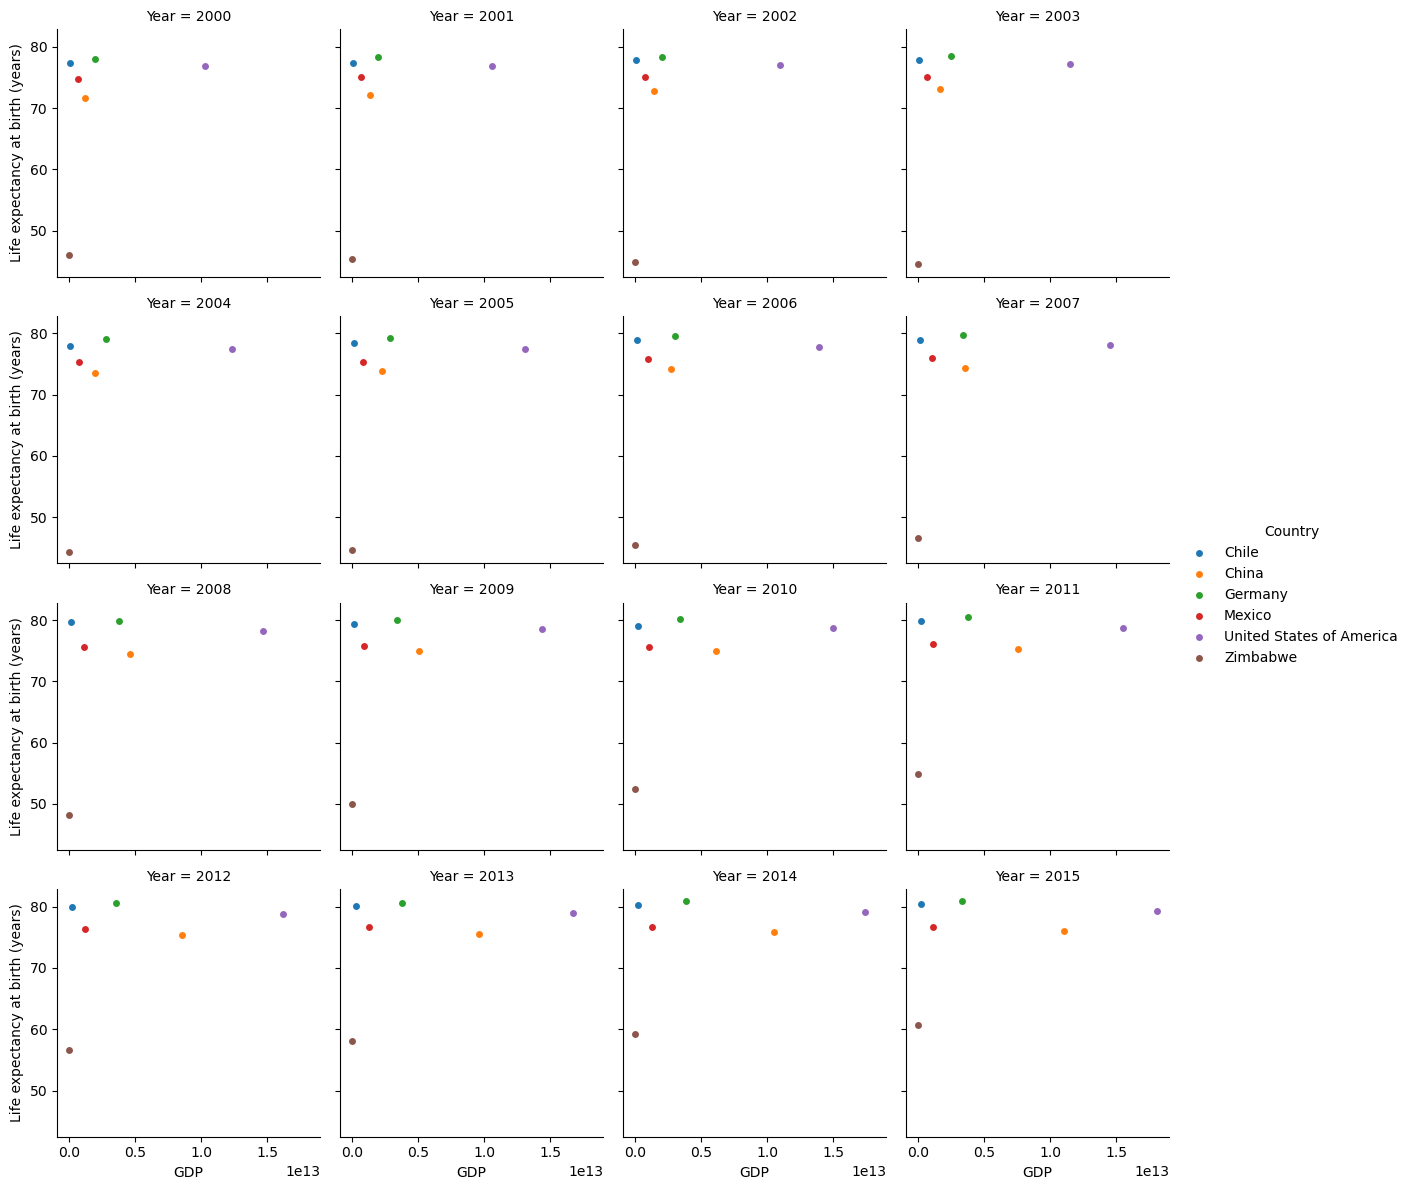

In [10]:
g = sns.FacetGrid(df, col="Year", hue="Country", col_wrap=4, height=3)
g.map(plt.scatter, "GDP", "Life expectancy at birth (years)", edgecolor="w")
g.add_legend()
plt.show()

Higher GDP correlates with higher life expectancy up to a certain threshold. Basic economic development heavily boosts health, but ultra-high wealth yields diminishing returns.

What is the distribution of the life expectancy?

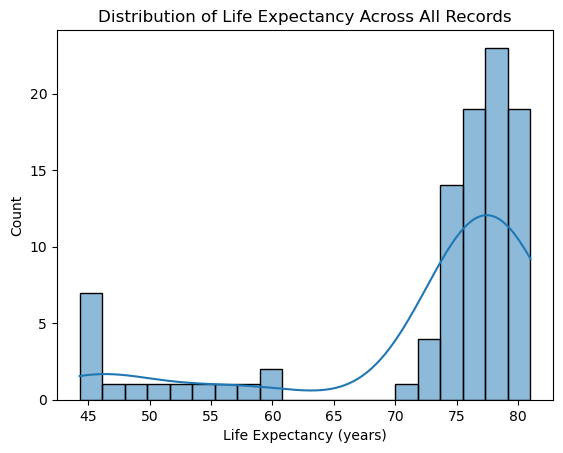

In [11]:
sns.histplot(df["Life expectancy at birth (years)"], kde=True, bins=20)
plt.title("Distribution of Life Expectancy Across All Records")
plt.xlabel("Life Expectancy (years)")
plt.show()

What we have here is a split, a bimodal disrubution. This data is heavily polarized into a high cluster and an outlier tail. A single mean would be misleading here and would not accurately represent any country. The vast majority of observations cluster tightly between 75 and 81 years, reflecting the stable, high-income health trajectories of nations such as the United States, Germany, the United Kingdom, Japan, and Chile.The vast majority of observations cluster tightly between 75 and 81 years, reflecting the stable, high-income health trajectories of nations such as the United States, Germany, the United Kingdom, Japan, and Chile.

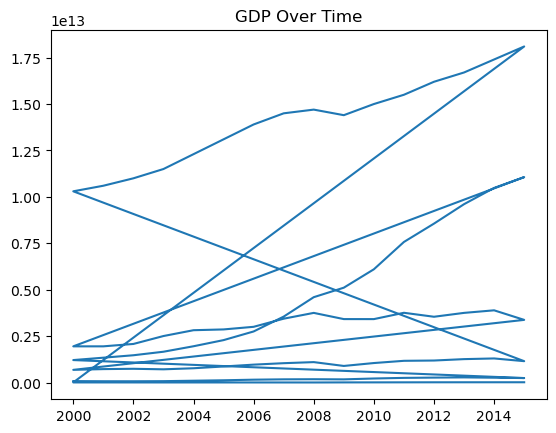

In [14]:
plt.plot(df["Year"], df["GDP"])
plt.title("GDP Over Time")
plt.savefig("my_chart.png", dpi=300)
plt.show()

Conclusions and Findings

1. Has life expectancy increased over time in the six nations?
Yes, longitudinal tracking from 2000 to 2015 demonstrates a clear, overall upward trajectory in life expectancy across every nation included in the dataset. While stable developed economies maintain high-end trajectories in the upper 70s to low 80s, developing nations showcase dramatic recoveries. Such as Zimbabwe’s sharp rebound past age 60 following historical mid-2000s health disruptions.

2. Has GDP increased over time in the six nations?
Yes, economic output expanded across all observed countries over the 15-year timespan. While the absolute scale of GDP varies drastically between nations(with major global superpowers exhibiting exponential economic scaling) every country experienced upward economic momentum.

3. Is there a correlation between GDP and life expectancy of a country? The multi-panel FacetGrid analysis reveals a strong, non-linear correlation between economic wealth and health outcomes. In lower-to-middle economic brackets, increases in GDP align with steep gains in life expectancy, reflecting how basic economic growth funds essential public health infrastructure, sanitation, and medical access. For wealthier, developed nations, the curve flattens significantly. Once a nation crosses a high economic threshold, further increases in GDP yield marginal health gains, shifting primary drivers toward lifestyle factors, advanced medical innovation, and public health policy.

4. What is the average life expectancy in these nations?Country-level aggregation reveals stark baseline disparities. Stable developed and upper-middle economies average consistently in the upper 70s and low 80s.   Nations that encountered severe historical health challenges exhibit lower multi-year averages that reflect their recovery timelines during the early 2000s.

5. What is the distribution of that life expectancy?The global distribution across all combined records is bimodal rather than a standard normal bell curve. The High Cluster: The vast majority of observations cluster tightly between 75 and 81 years, capturing stable baseline health outcomes. The Lower Outlier Tail: A distinct lower grouping appears between 44 and 60 years, driven entirely by historical data points from developing contexts undergoing severe regional health crises. This polarization proves that relying on a single global average is statistically misleading, as it compresses two distinct socioeconomic realities into one unrepresentative figure.  